## Imports y funciones base

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import subprocess
import joblib
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit
import csv


sys.path.insert(0, str(Path.cwd().parent / "src"))
from train_model import (cargar_conjuntos, baseline_persistencia, baseline_media_movil, evaluar,
                         registrar_experimento, optimizar, entrenar_y_evaluar, guardar_seleccion)

SEED = 42

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
conjuntos, features = cargar_conjuntos()
train, val = conjuntos["train"], conjuntos["val"]   # test queda en conjuntos["test"]: se usa una sola vez, al final
X_train, y_train = train[features], train["target"]
X_val, y_val = val[features], val["target"]
print(f"{len(features)} features | X_train {X_train.shape} | X_val {X_val.shape}")

train: 849 días | 2020-07-01 -> 2022-10-27
val: 182 días | 2022-10-28 -> 2023-04-27
test: 182 días | 2023-04-28 -> 2023-10-26
41 features | X_train (849, 41) | X_val (182, 41)


## Creación de los baselines

In [29]:
frio = "Consolidado EE | Frio (Kw)"
coincide = (val["target"].iloc[:-1].to_numpy() == val[frio].iloc[1:].to_numpy()).mean()
print(f"target[D] == Frío[D+1] en el {coincide:.1%} de los días de validación")

target[D] == Frío[D+1] en el 100.0% de los días de validación


In [30]:
predicciones_base = {
    "persistencia": baseline_persistencia(val),
    "media_movil_7": baseline_media_movil(val, previo=train),
}

resultados_base = {}
for nombre, pred in predicciones_base.items():
    metricas = evaluar(y_val, pred)
    registrar_experimento(nombre, "validacion", metricas, semilla=SEED)
    resultados_base[nombre] = metricas

pd.DataFrame(resultados_base).T.round({"mae": 0, "rmse": 0, "r2": 3})

,mae,rmse,r2
persistencia,2700.0,3360.0,0.246
media_movil_7,2455.0,3299.0,0.273


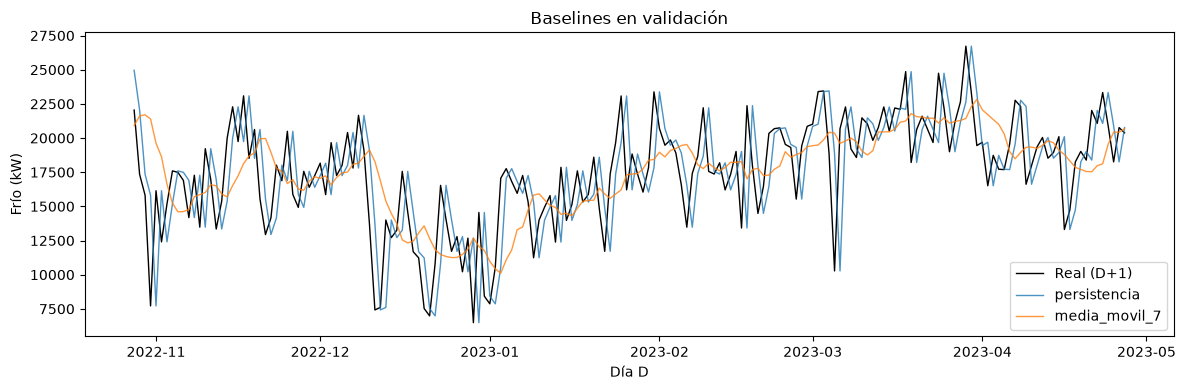

In [31]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(val["DIA"], y_val, label="Real (D+1)", color="black", linewidth=1)
for nombre, pred in predicciones_base.items():
    ax.plot(val["DIA"], pred, label=nombre, linewidth=1, alpha=0.8)
ax.set_xlabel("Día D")
ax.set_ylabel("Frío (kW)")
ax.set_title("Baselines en validación")
ax.legend()
plt.tight_layout()
plt.show()

## Experimentos

In [32]:
def espacio_ridge(trial):
    return {"alpha": trial.suggest_float("alpha", 1e-3, 1e5, log=True)}


def espacio_lasso(trial):
    return {"alpha": trial.suggest_float("alpha", 1, 1e4, log=True)}


def espacio_random_forest(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 40),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 40),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
        "max_samples": trial.suggest_float("max_samples", 0.5, 1.0),
    }


def espacio_xgboost(trial):
    return {
        "objective": trial.suggest_categorical("objective", ["reg:squarederror", "reg:absoluteerror"]),
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "colsample_bylevel": trial.suggest_float("colsample_bylevel", 0.5, 1.0),
        "colsample_bynode": trial.suggest_float("colsample_bynode", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 1e4, log=True),
    }


def espacio_lightgbm(trial):
    return {
        "objective": trial.suggest_categorical("objective", ["regression", "regression_l1"]),
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 128, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "feature_fraction_bynode": trial.suggest_float("feature_fraction_bynode", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 1e4, log=True),
        "extra_trees": trial.suggest_categorical("extra_trees", [False, True]),
    }

In [33]:
for nombre, espacio in [("ridge", espacio_ridge), ("lasso", espacio_lasso),
                        ("random_forest", espacio_random_forest), ("xgboost", espacio_xgboost),
                        ("lightgbm", espacio_lightgbm)]:
    optimizar(nombre, espacio, X_train, y_train, n_trials=3, semilla=SEED, registrar=False)

ridge: 3 completos, 0 podados | MAE CV 2,951 ± 422 kW
lasso: 3 completos, 0 podados | MAE CV 2,901 ± 301 kW
random_forest: 3 completos, 0 podados | MAE CV 3,144 ± 230 kW
xgboost: 3 completos, 0 podados | MAE CV 3,188 ± 293 kW
lightgbm: 3 completos, 0 podados | MAE CV 3,208 ± 423 kW


In [34]:
estudio_ridge = optimizar("ridge", espacio_ridge, X_train, y_train, n_trials=200, semilla=SEED)

ridge: 30 completos, 170 podados | MAE CV 2,919 ± 357 kW


In [35]:
estudio_lasso = optimizar("lasso", espacio_lasso, X_train, y_train, n_trials=200, semilla=SEED)

lasso: 72 completos, 128 podados | MAE CV 2,897 ± 294 kW


In [36]:
estudio_rf = optimizar("random_forest", espacio_random_forest, X_train, y_train,
                       n_trials=2000, timeout=int(1.5 * 3600), semilla=SEED)

random_forest: 218 completos, 1782 podados | MAE CV 3,060 ± 202 kW


In [52]:
estudio_xgb = optimizar("xgboost", espacio_xgboost, X_train, y_train,
                        n_trials=2000, timeout=2 * 3600, semilla=SEED)

  0%|          | 0/2000 [00:00<?, ?it/s]

xgboost: 339 completos, 1661 podados | MAE CV 3,064 ± 278 kW


In [39]:
estudio_lgbm = optimizar("lightgbm", espacio_lightgbm, X_train, y_train,
                         n_trials=500, timeout=2 * 3600, semilla=SEED)

lightgbm: 209 completos, 291 podados | MAE CV 3,077 ± 263 kW


In [53]:
estudios = {"ridge": estudio_ridge, "lasso": estudio_lasso, "random_forest": estudio_rf,
            "xgboost": estudio_xgb, "lightgbm": estudio_lgbm}
pd.DataFrame({n: {"mae_cv": e.best_value,
                  "desvio_folds": e.best_trial.user_attrs["mae_desvio_folds"],
                  "trials": len(e.trials),
                  "podados": sum(t.state.name == "PRUNED" for t in e.trials)}
              for n, e in estudios.items()}).T.round(0)

,mae_cv,desvio_folds,trials,podados
ridge,2919.0,357.0,200.0,170.0
lasso,2897.0,294.0,200.0,128.0
random_forest,3060.0,202.0,2000.0,1782.0
xgboost,3064.0,278.0,2000.0,1661.0
lightgbm,3077.0,263.0,500.0,291.0


## Logs de Experimentos

El script train_model es el que los trabaja y guarda los logs en results.

In [ ]:
ruta_log = Path.cwd().parent / "results" / "experiment_logs.csv"
with open(ruta_log, encoding="utf-8", newline="") as f:
    filas = list(csv.reader(f))

rotos = sum(len(fila) == 1 for fila in filas)
if rotos:
    filas = [next(csv.reader([fila[0]])) if len(fila) == 1 else fila for fila in filas]
    with open(ruta_log, "w", encoding="utf-8", newline="") as f:
        csv.writer(f, lineterminator="\n").writerows(filas)

log = pd.read_csv(ruta_log, parse_dates=["timestamp"])
log["hiperparametros"] = log["hiperparametros"].apply(json.loads)

Renglones reparados: 0


In [61]:
# Un experimento = filas cv_train seguidas del mismo modelo y n_features; cuando la numeración de trials vuelve a empezar, empieza otro
cv = log[log["conjunto"] == "cv_train"].copy()
nuevo = ((cv["modelo"] != cv["modelo"].shift()) | (cv["trial"] <= cv["trial"].shift())
         | (cv["n_features"] != cv["n_features"].shift()))
cv["experimento"] = nuevo.cumsum()


def resumir(g):
    mejor = g.loc[g["mae"].idxmin()]
    return pd.Series({
        "modelo": mejor["modelo"], "inicio": g["timestamp"].min(), "n_features": int(mejor["n_features"]),
        "mae_cv": mejor["mae"], "desvio_folds": mejor["mae_desvio_folds"],
        "trials": len(g),
        "mejores_hiperparametros": {k: round(v, 4) if isinstance(v, float) else v
                                    for k, v in mejor["hiperparametros"].items()},
    })


tabla_experimentos = cv.groupby("experimento").apply(resumir, include_groups=False)
with pd.option_context("display.max_colwidth", None):
    display(tabla_experimentos.round({"mae_cv": 0, "desvio_folds": 0}))

,modelo,inicio,n_features,mae_cv,desvio_folds,trials,mejores_hiperparametros
experimento,,,,,,,
1,ridge,2026-11-15 03:32:12,37,2944.0,315.0,27,{'alpha': 90.3684}
2,lasso,2026-11-15 03:32:14,37,2935.0,282.0,43,{'alpha': 47.6384}
3,random_forest,2026-11-15 03:32:19,37,3072.0,206.0,160,"{'n_estimators': 800, 'max_depth': 14, 'min_samples_split': 5, 'min_samples_leaf': 7, 'max_features': 0.6251, 'max_samples': 0.5077}"
4,xgboost,2026-11-15 05:02:21,37,3002.0,360.0,635,"{'objective': 'reg:squarederror', 'n_estimators': 300, 'learning_rate': 0.0286, 'max_depth': 3, 'min_child_weight': 1.4047, 'subsample': 0.75, 'colsample_bytree': 0.4392, 'colsample_bylevel': 0.6788, 'colsample_bynode': 0.5798, 'reg_lambda': 0.0026, 'reg_alpha': 0.1757}"
5,lightgbm,2026-11-15 05:39:53,37,3003.0,337.0,455,"{'objective': 'regression_l1', 'n_estimators': 1650, 'learning_rate': 0.0438, 'num_leaves': 13, 'max_depth': 12, 'min_child_samples': 54, 'subsample': 0.9291, 'colsample_bytree': 0.6617, 'feature_fraction_bynode': 0.7985, 'reg_lambda': 0.4333, 'reg_alpha': 0.7663, 'extra_trees': False}"
6,ridge,2026-11-15 10:39:56,41,2919.0,357.0,30,{'alpha': 21.7552}
7,lasso,2026-11-15 10:40:02,41,2897.0,294.0,72,{'alpha': 38.6517}
8,random_forest,2026-11-15 10:40:10,41,3060.0,202.0,218,"{'n_estimators': 150, 'max_depth': 11, 'min_samples_split': 10, 'min_samples_leaf': 7, 'max_features': 0.5708, 'max_samples': 0.7098}"
9,xgboost,2026-11-15 11:04:00,41,3108.0,310.0,34,"{'objective': 'reg:squarederror', 'n_estimators': 800, 'learning_rate': 0.0117, 'max_depth': 2, 'min_child_weight': 39.9526, 'subsample': 0.6286, 'colsample_bytree': 0.6772, 'colsample_bylevel': 0.7739, 'colsample_bynode': 0.7801, 'reg_lambda': 3.8353, 'reg_alpha': 0.0032}"


Para los arboles, me quedo con el 8 y el 12, el random forest y el xgboost que so nlos dos últimos que corrí con la combinación correcta de features.

Para LASSO/Ridge, me quedo con los últimos (6 y 7). 

## Comparo sobre los mismos folds

In [ ]:

# Modelos del log (por número de experimento de tabla_experimentos) + baselines, sobre los mismos 4 folds que usa optimizar
experimentos_a_comparar = {"rf_corrida2": 8, "xgb_corrida2": 12, "lgbm_corrida2": 11, "lasso_corrida2": 7}

In [ ]:

folds = list(TimeSeriesSplit(n_splits=4, test_size=91).split(X_train))
nombres_folds = [f"{train['DIA'].iloc[idx].min():%Y-%m} a {train['DIA'].iloc[idx].max():%Y-%m}" for _, idx in folds]

predicciones_base_train = {"persistencia": baseline_persistencia(train),
                           "media_movil_7": baseline_media_movil(train)}   # solo miran hacia atrás: se calculan sobre todo train
maes_folds = {n: [evaluar(y_train.iloc[idx], p.iloc[idx])["mae"] for _, idx in folds]
              for n, p in predicciones_base_train.items()}
mae_cv_log = {}

for nombre, num in experimentos_a_comparar.items():
    filas_exp = cv[cv["experimento"] == num]
    mejor = filas_exp.loc[filas_exp["mae"].idxmin()]
    if mejor["n_features"] != len(features):
        print(f"Aviso: {nombre} (experimento {num}) se buscó con {int(mejor['n_features'])} features "
              f"y ahora hay {len(features)}: se entrena con las actuales")
    maes_folds[nombre] = [entrenar_y_evaluar(mejor["modelo"], mejor["hiperparametros"], train.iloc[idx_aj],
                                             train.iloc[idx_ev], features, "cv_train", semilla=SEED,
                                             registrar=False)[2]["mae"]
                          for idx_aj, idx_ev in folds]
    mae_cv_log[nombre] = mejor["mae"]

tabla_folds = pd.DataFrame(maes_folds, index=nombres_folds).T
tabla_folds["mae_cv"] = tabla_folds[nombres_folds].mean(axis=1)
tabla_folds["desvio_folds"] = tabla_folds[nombres_folds].std(axis=1, ddof=0)
tabla_folds["mae_cv_log"] = pd.Series(mae_cv_log)      # control: tiene que coincidir con mae_cv
tabla_folds.sort_values("mae_cv").round(0)

,mae_cv,desvio_folds
persistencia,3506.0,437.0
media_movil_7,3641.0,515.0


In [ ]:
resultados_val, predicciones_val = {}, {}
for nombre, estudio in estudios.items():
    _, pred, metricas = entrenar_y_evaluar(nombre, estudio.best_params, train, val, features,
                                           "validacion", semilla=SEED)
    resultados_val[nombre] = {**metricas, "mae_cv": estudio.best_value}
    predicciones_val[nombre] = pred

tabla_val = pd.DataFrame({**resultados_val, **resultados_base}).T
mejor_base = tabla_val.loc[list(resultados_base), "mae"].min()
tabla_val["mejora_vs_mejor_baseline_%"] = (1 - tabla_val["mae"] / mejor_base) * 100
tabla_val.sort_values("mae").round({"mae": 0, "rmse": 0, "r2": 3, "mae_cv": 0, "mejora_vs_mejor_baseline_%": 1})

,mae,rmse,r2,mae_cv,mejora_vs_mejor_baseline_%
random_forest,2215.0,2860.0,0.454,3060.0,9.8
xgboost,2272.0,2883.0,0.445,3064.0,7.5
lightgbm,2318.0,2955.0,0.417,3077.0,5.6
media_movil_7,2455.0,3299.0,0.273,NaN,0.0
persistencia,2700.0,3360.0,0.246,NaN,-9.9
lasso,2923.0,3670.0,0.101,2897.0,-19.0
ridge,3108.0,3883.0,-0.007,2919.0,-26.6


In [ ]:
elegido = tabla_val.drop(index=list(resultados_base))["mae"].idxmin()
print(f"Modelo elegido: {elegido} | MAE validación {tabla_val.loc[elegido, 'mae']:,.0f} "
      f"| mejora sobre el mejor baseline: {tabla_val.loc[elegido, 'mejora_vs_mejor_baseline_%']:.1f} %")

Modelo elegido: random_forest | MAE validación 2,215 | mejora sobre el mejor baseline: 9.8 %


## Graficos

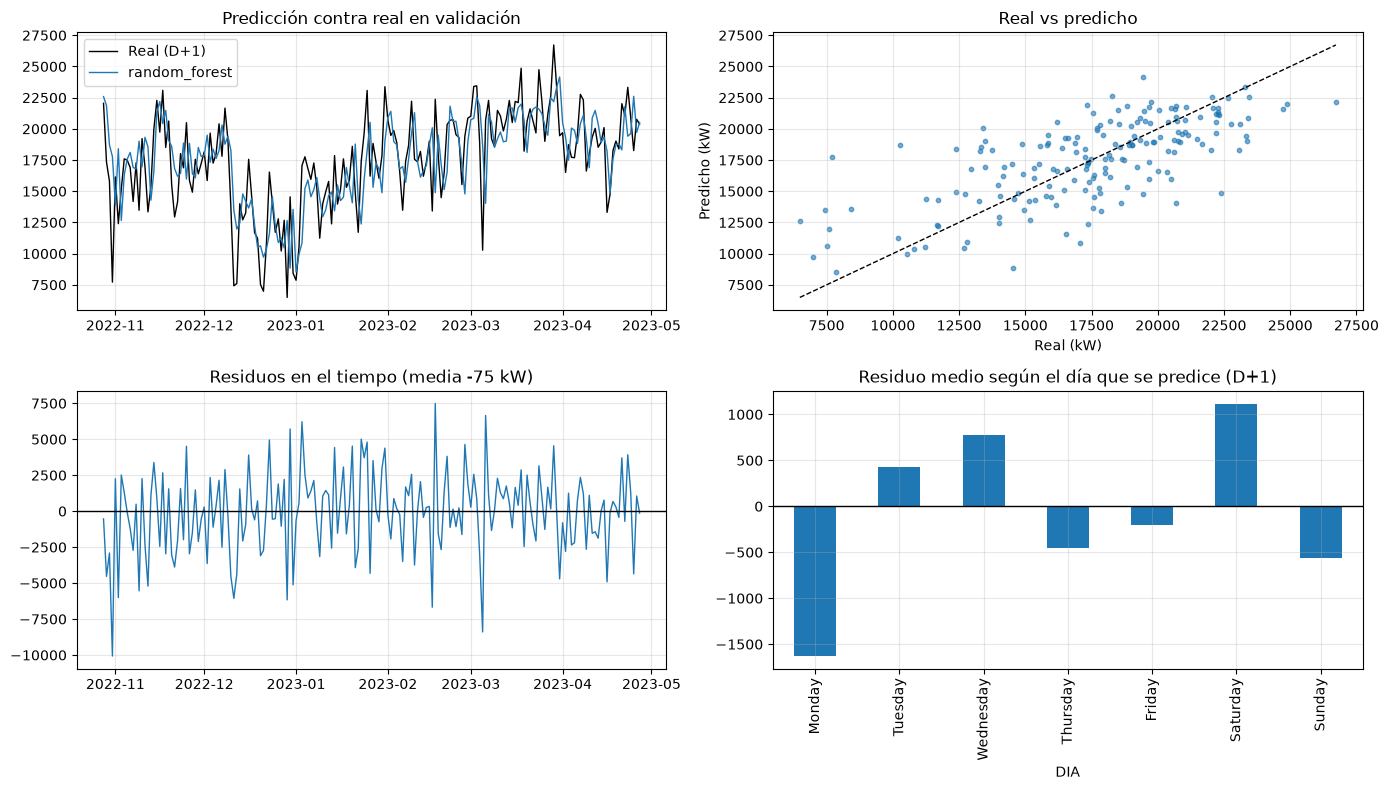

In [57]:
pred = predicciones_val[elegido]
residuo = y_val - pred
dia_d1 = (val["DIA"] + pd.Timedelta(days=1)).dt.day_name()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(val["DIA"], y_val, label="Real (D+1)", color="black", linewidth=1)
axes[0, 0].plot(val["DIA"], pred, label=elegido, linewidth=1)
axes[0, 0].set_title("Predicción contra real en validación"); axes[0, 0].legend()

lim = [min(y_val.min(), pred.min()), max(y_val.max(), pred.max())]
axes[0, 1].scatter(y_val, pred, s=10, alpha=0.6)
axes[0, 1].plot(lim, lim, color="black", linestyle="--", linewidth=1)
axes[0, 1].set_xlabel("Real (kW)"); axes[0, 1].set_ylabel("Predicho (kW)"); axes[0, 1].set_title("Real vs predicho")

axes[1, 0].plot(val["DIA"], residuo, linewidth=1)
axes[1, 0].axhline(0, color="black", linewidth=1)
axes[1, 0].set_title(f"Residuos en el tiempo (media {residuo.mean():,.0f} kW)")

orden = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
residuo.groupby(dia_d1).mean().reindex(orden).plot.bar(ax=axes[1, 1])
axes[1, 1].axhline(0, color="black", linewidth=1)
axes[1, 1].set_title("Residuo medio según el día que se predice (D+1)")

for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()